# Substrata analyses for Madracis spp.

In [1]:
%load_ext autoreload
%autoreload 2
from substrata import *
import os
project_root = r"C:\Users\deepcat\projects\substrata_notebooks\jennifer"

C:\Users\deepcat\AppData\Local\miniconda3\envs\substrata\lib\site-packages\tqdm_joblib\__init__.py:4: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


## Define paths, plots, and substrata functions

In [2]:
# Defining paths and plot ids
# Note that Annotations files need to have a header: id,x,y,z,label,species
annotations_path = os.path.join(project_root, "annotations/")
microhabitat_output_path = os.path.join(project_root, "microhabitat/output/")
microhabitat_vis_path = os.path.join(project_root, "microhabitat/visualizations/")
plot_vis_path = os.path.join(project_root, "plot_visualizations/")
plot_paths = {
#    'cur_sna_05m_20200303': 'Y:/focal_plots/cur_sna/cur_sna_05m/cur_sna_05m_20200303/',
#    'cur_sna_10m_20200303': 'Y:/focal_plots/cur_sna/cur_sna_10m/cur_sna_10m_20200303/',
#    'cur_sna_20m_20200303': 'Y:/focal_plots/cur_sna/cur_sna_20m/cur_sna_20m_20200303/',
#    'cur_sna_40m_20200216': 'Y:/focal_plots/cur_sna/cur_sna_40m/cur_sna_40m_20200216/',
#    'cur_kal_05m_20200214': 'Y:/focal_plots/cur_kal/cur_kal_05m/cur_kal_05m_20200214/',
#    'cur_kal_10m_20200214': 'Y:/focal_plots/cur_kal/cur_kal_10m/cur_kal_10m_20200214/',
#    'cur_kal_20m_20200214': 'Y:/focal_plots/cur_kal/cur_kal_20m/cur_kal_20m_20200214/',
#    'cur_kal_40m_20200214': 'Y:/focal_plots/cur_kal/cur_kal_40m/cur_kal_40m_20200214/',
#    'cur_est_05m_20200219': 'Y:/focal_plots/cur_est/cur_est_05m/cur_est_05m_20200219/',
#    'cur_est_10m_20200219': 'Y:/focal_plots/cur_est/cur_est_10m/cur_est_10m_20200219/',
#    'cur_est_20m_20200219': 'Y:/focal_plots/cur_est/cur_est_20m/cur_est_20m_20200219/',
#    'cur_est_40m_20200219': 'Y:/focal_plots/cur_est/cur_est_40m/cur_est_40m_20200219/',
    'cur_est_60m_20200302': 'Y:/focal_plots/cur_est/cur_est_60m/cur_est_60m_20200302/' 
}

In [3]:
def execute_all_steps(): 
    for plot_id in plot_paths:
        plot_path = plot_paths[plot_id]
        plot_annotations_path = os.path.join(annotations_path, f"{plot_id}_updated_spp.csv")
        
        plot = load_plot_and_annotations(plot_id, plot_path, plot_annotations_path)
        # calc_distance_matrix(plot, output_path)
        calc_microhabitat_measurements(plot, microhabitat_output_path)

### Test substrata for one plot

#### Loads plot and annotations. Check to make sure sna_05 and est_40 transformed annotations are on plot

In [4]:
def load_plot_and_annotations(plot, plot_path, annotations_path):
    plot = ProjectInitializer(yaml = plot_path + plot + ".yaml")
    plot.reset_paths_to_local(plot_path)        # not required when running on server
    plot.annotations_filepath = annotations_path
    plot.initialize()
    return plot

# Example execution
# plot = load_plot_and_annotations('cur_est_40m_20200219',
#                                  plot_paths['cur_est_40m_20200219'],
#                                  os.path.join(annotations_path, 'cur_est_40m_20200219_updated_spp.csv'))
# Visualize annotations
# plot.annotations.show(plot.pcd, color=True)

### Runs substrata functions on test plot to confirm everything looks good

In [5]:
def calc_microhabitat_measurements(plot, output_path, trial_run=False):
    if trial_run:
        annotations = plot.annotations.subset(5)
    else:
        annotations = plot.annotations
    measurements_output_filepath = os.path.join(output_path, f'{plot.id}_measurements.csv')
    # Sample point cloud around annotations with 0.2m radius
    annotations.get_point_cloud_by_radius(plot.pcd, 0.2)
    # Calculate microhabitat measurements
    annotations.measure_all(calc_gap_fraction, plot.pcd.simple_pcd)
    annotations.measure_all(calc_roughness)
    annotations.measure_all(get_vector_dispersion)
    annotations.measure_all(get_plane_angles)
    # Save microhabitat measurements
    annotations.save(measurements_output_filepath)
    pdf_path = os.path.join(microhabitat_vis_path,f"{plot.id}_measurements.pdf")
    visualizations.save_measurement_visualizations_to_pdf(annotations, pdf_path)

# Example execution
# calc_microhabitat_measurements(plot, microhabitat_output_path, trial_run=True)

## Calculate habitat measurements for all plots

In [6]:
execute_all_steps()

Loading project from YAML file: Y:/focal_plots/cur_est/cur_est_60m/cur_est_60m_20200302/cur_est_60m_20200302.yaml
Loading pointcloud from Y:\focal_plots\cur_est\cur_est_60m\cur_est_60m_20200302\cur_est_60m_20200302_dec50M.ply
Loading cameras from Y:\focal_plots\cur_est\cur_est_60m\cur_est_60m_20200302\cur_est_60m_20200302.meta.json and Y:\focal_plots\cur_est\cur_est_60m\cur_est_60m_20200302\cur_est_60m_20200302.cams.xml
Loading markers from Y:\focal_plots\cur_est\cur_est_60m\cur_est_60m_20200302\cur_est_60m_20200302_markers.csv
Loading annotations from C:\Users\deepcat\projects\substrata_notebooks\jennifer\annotations/cur_est_60m_20200302_updated_spp.csv
Applying world_transform to loaded objects:
[[-5.31137914e-03 -1.22825761e-01  2.82727596e-02  2.39751662e+01]
 [ 1.05612336e-01 -1.97810206e-02 -6.60944235e-02  2.92002615e+00]
 [ 6.87862693e-02  2.08870990e-02  1.03662459e-01 -5.89068775e+01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


Subsampling pointcloud for each annotation: 100%|██████████████████████████████████████| 14/14 [01:07<00:00,  4.85s/it]
Conducting <function calc_gap_fraction at 0x000002155C1379A0> measurement for all annotations...:   0%| | 0/14 [00:00<?

  0%|          | 0/14 [00:00<?, ?it/s]


Conducting <function calc_roughness at 0x000002155C1372E0> measurement for all annotations...:   0%| | 0/14 [00:00<?, ?

  0%|          | 0/14 [00:00<?, ?it/s]



Conducting <function get_vector_dispersion at 0x000002155C137400> measurement for all annotations...:   0%| | 0/14 [00:

  0%|          | 0/14 [00:00<?, ?it/s]

Conducting <function calc_roughness at 0x000002155C1372E0> measurement for all annotations...:   0%| | 0/14 [00:31<?, ?

Conducting <function get_plane_angles at 0x000002155C137130> measurement for all annotations...:   0%| | 0/14 [00:00<?,

  0%|          | 0/14 [00:00<?, ?it/s]

Conducting <function get_plane_angles at 0x000002155C137130> measurement for all annotations...:   0%| | 0/14 [00:18<?,


PDF created: C:\Users\deepcat\projects\substrata_notebooks\jennifer\microhabitat/visualizations/cur_est_60m_20200302_measurements.pdf


## Rerunning substrata for colonies that had gap fill issues

In [218]:
# Defining paths and plot ids
# Note that Annotations files need to have a header: id,x,y,z,label,species
annotations_path = os.path.join(project_root, "annotations/")
microhabitat_output_path = os.path.join(project_root, "microhabitat/output/")
microhabitat_vis_path = os.path.join(project_root, "microhabitat/visualizations/")
plot_vis_path = os.path.join(project_root, "plot_visualizations/")
plot_paths = {
#    'cur_sna_05m_20200303': 'Y:/focal_plots/cur_sna/cur_sna_05m/cur_sna_05m_20200303/',
    'cur_sna_20m_20200303': 'Y:/focal_plots/cur_sna/cur_sna_20m/cur_sna_20m_20200303/',
#    'cur_kal_10m_20200214': 'Y:/focal_plots/cur_kal/cur_kal_10m/cur_kal_10m_20200214/',
#    'cur_kal_20m_20200214': 'Y:/focal_plots/cur_kal/cur_kal_20m/cur_kal_20m_20200214/',
#    'cur_kal_40m_20200214': 'Y:/focal_plots/cur_kal/cur_kal_40m/cur_kal_40m_20200214/',
#    'cur_est_05m_20200219': 'Y:/focal_plots/cur_est/cur_est_05m/cur_est_05m_20200219/',
#    'cur_est_10m_20200219': 'Y:/focal_plots/cur_est/cur_est_10m/cur_est_10m_20200219/',
#    'cur_est_20m_20200219': 'Y:/focal_plots/cur_est/cur_est_20m/cur_est_20m_20200219/',
#    'cur_est_40m_20200219': 'Y:/focal_plots/cur_est/cur_est_40m/cur_est_40m_20200219/'
}

Loading project from YAML file: Y:/focal_plots/cur_sna/cur_sna_20m/cur_sna_20m_20200303/cur_sna_20m_20200303.yaml
Loading pointcloud from Y:\focal_plots\cur_sna\cur_sna_20m\cur_sna_20m_20200303\cur_sna_20m_20200303_dec50M.ply
Loading cameras from Y:\focal_plots\cur_sna\cur_sna_20m\cur_sna_20m_20200303\cur_sna_20m_20200303.meta.json and Y:\focal_plots\cur_sna\cur_sna_20m\cur_sna_20m_20200303\cur_sna_20m_20200303.cams.xml
Loading markers from Y:\focal_plots\cur_sna\cur_sna_20m\cur_sna_20m_20200303\cur_sna_20m_20200303_markers.csv
Loading annotations from C:\Users\deepcat\projects\substrata_notebooks\jennifer\annotations/cur_sna_20m_20200303_gapfill_redo.csv
Applying world_transform to loaded objects:
[[ 3.23942793e-02 -1.28868293e-01  5.01961939e-02  9.95935258e+00]
 [ 1.16217535e-01 -2.58064670e-03 -8.16266435e-02  2.83268348e+00]
 [ 7.49678554e-02  5.96857393e-02  1.04849975e-01 -1.92885183e+01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


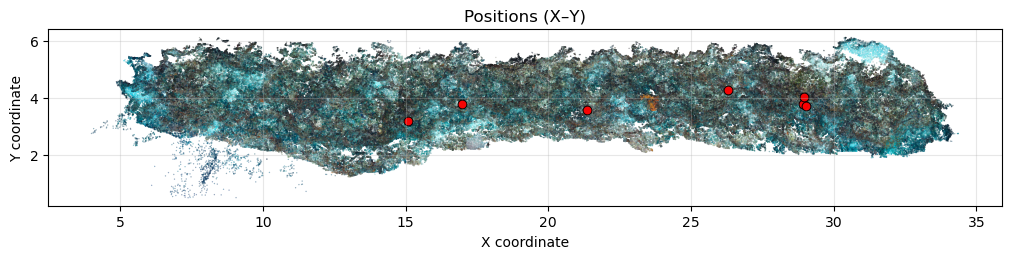

In [219]:
def load_plot_and_annotations(plot_path, annotations_path):
    plot = ProjectInitializer(path = plot_path)
    plot.reset_paths_to_local(plot_path)        # not required when running on server
    plot.annotations_filepath = annotations_path
    plot.initialize()
    return plot

# Example execution
plot = load_plot_and_annotations(plot_paths['cur_sna_20m_20200303'],
                                 os.path.join(annotations_path, 'cur_sna_20m_20200303_gapfill_redo.csv'))
# Visualize annotations
plot.annotations.show(plot.pcd, color=True)

In [229]:
# define the annotation for which gap_fraction needs to be redone
annotation = plot.annotations['JH_0697']

In [230]:
# calculate gap_fraction, both seed_point coords are right in the middle [(0.5, 0.5), (0.5, 0.5)]
gapF_raw, gapF_fill, gapF_image = calc_gap_fraction(annotation, plot.pcd.simple_pcd, seed_points=[(0.1, 0.5), (0.5, 0.5)])

0.3790545917555308 0.16087856119688046


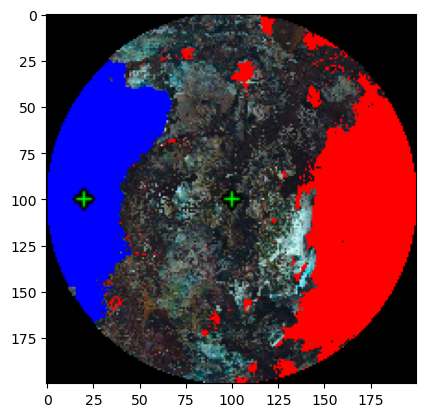

In [231]:
# visualize
print(gapF_raw, gapF_fill)
plt.imshow(gapF_image)
plt.show()

In [6]:
print(calc_gap_fraction.__doc__)


    Calculate gap fraction based on hemispherical projection:
    ratio of "sky pixels" to "benthic pixels" in the resulting 2D image

    Args:
        annotation: Annotation object with coords attribute.
        pcd: Point cloud object.
        resolution: Image resolution (default 200).
        color_output: Whether to use color output (default True).
        max_radius: Optional maximum radius for filtering points.
        output_filename: Optional filename to save the image. If None, the image
            is not saved to file. If not provided, uses default path based on
            annotation.id and settings.OUTPUT_FOLDER.
    
